# IronKaggle – Sales Prediction

Corrected notebook using leakage-safe store-level features.

**Important:** Keep `sales.csv` and `validation_for_students.csv` in the same folder as this notebook.

Import the libraries used for data preparation, model training, cross-validation, and evaluation.

In [1]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, KFold
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error


Load the labeled training data and the rows for which sales must be predicted.

In [2]:
df = pd.read_csv("sales.csv", index_col=0)
real = pd.read_csv("validation_for_students.csv", index_col=0)

# Match mirror header capitalization to the training column names.
column_names = {column.lower(): column for column in df.columns}
real = real.rename(columns={
    column: column_names.get(column.lower(), column)
    for column in real.columns
})

print("Training data shape:", df.shape)
print("Prediction data shape:", real.shape)


Training data shape: (640840, 9)
Prediction data shape: (71205, 8)


Preview the training rows and inspect the data types and column details.

In [3]:
display(df.head())
df.info()


<class 'pandas.core.frame.DataFrame'>
Index: 640840 entries, 425390 to 305711
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype 
---  ------               --------------   ----- 
 0   store_ID             640840 non-null  int64 
 1   day_of_week          640840 non-null  int64 
 2   date                 640840 non-null  object
 3   nb_customers_on_day  640840 non-null  int64 
 4   open                 640840 non-null  int64 
 5   promotion            640840 non-null  int64 
 6   state_holiday        640840 non-null  object
 7   school_holiday       640840 non-null  int64 
 8   sales                640840 non-null  int64 
dtypes: int64(7), object(2)
memory usage: 48.9+ MB


,store_ID,day_of_week,date,nb_customers_on_day,open,promotion,state_holiday,school_holiday,sales
425390,366,4,2013-04-18,517,1,0,0,0,4422
291687,394,6,2015-04-11,694,1,0,0,0,8297
411278,807,4,2013-08-29,970,1,1,0,0,9729
664714,802,2,2013-05-28,473,1,1,0,0,6513
540835,726,4,2013-10-10,1068,1,1,0,0,10882


Check missing values, holiday labels, stores, dates, and the sales target.

In [4]:
print("Missing values:", df.isna().sum().sum())
print("Holiday values:", df["state_holiday"].unique())
print("Number of stores:", df["store_ID"].nunique())
print("Date range:", df["date"].min(), "to", df["date"].max())
display(df["sales"].describe())
print("Sales when the store is closed:", df.loc[df["open"] == 0, "sales"].unique())
print("Customer-sales correlation:", round(df["nb_customers_on_day"].corr(df["sales"]), 3))


Missing values: 0
Holiday values: ['0' 'a' 'c' 'b']
Number of stores: 1115
Date range: 2013-01-01 to 2015-07-31
Sales when the store is closed: [0]
Customer-sales correlation: 0.895


count    640840.000000
mean       5777.469011
std        3851.338083
min           0.000000
25%        3731.000000
50%        5746.000000
75%        7860.000000
max       41551.000000
Name: sales, dtype: float64

Convert ISO year-month-day dates from both mirror CSVs to calendar features and one-hot encode holidays.

In [5]:
def add_features(data, dayfirst=False):
    data = data.copy()
    data["date"] = pd.to_datetime(data["date"], dayfirst=dayfirst, errors="raise")

    data["year"] = data["date"].dt.year - 2013
    data["month"] = data["date"].dt.month
    data["day"] = data["date"].dt.day

    holiday = pd.get_dummies(data["state_holiday"], prefix="holiday")
    data = pd.concat([data, holiday], axis=1)

    return data.drop(columns=["date", "state_holiday"])


data = add_features(df, dayfirst=False)
real_p = add_features(real, dayfirst=False)

holiday_columns = ["holiday_0", "holiday_a", "holiday_b", "holiday_c"]

for column in holiday_columns:
    if column not in data.columns:
        data[column] = 0
    if column not in real_p.columns:
        real_p[column] = 0

# Ensure that both datasets have the same holiday feature columns.
real_p = real_p.reindex(columns=data.columns.drop("sales"), fill_value=0)

print("Training feature missing values:", data.isna().sum().sum())
print("Prediction feature missing values:", real_p.isna().sum().sum())


Training feature missing values: 0
Prediction feature missing values: 0


Split the labeled data into training and held-out test sets. Keep one quarter for evaluation. Define the metrics used to compare models.

In [6]:
train, test = train_test_split(data, test_size=0.25, random_state=10)

print("Training partition:", train.shape)
print("Test partition:", test.shape)

base_feats = [column for column in data.columns if column != "sales"]

def metrics(y_true, y_pred):
    return (
        r2_score(y_true, y_pred),
        mean_squared_error(y_true, y_pred),
        mean_absolute_error(y_true, y_pred),
    )


Training partition: (480630, 14)
Test partition: (160210, 14)


Fit a Linear Regression baseline using the original numeric features. This provides a reference score before adding store-level information.

In [7]:
baseline = LinearRegression()
baseline.fit(train[base_feats], train["sales"])

baseline_metrics = metrics(
    test["sales"],
    baseline.predict(test[base_feats])
)

print(
    "Linear Regression baseline: R2=%.4f  MSE=%.0f  MAE=%.1f"
    % baseline_metrics
)


Linear Regression baseline: R2=0.8543  MSE=2155023  MAE=984.1


Create store-level statistics using only a supplied source dataset. When a store is absent from the source, use global fallback statistics from that same source.

In [8]:
STORE_FEATURES = [
    "store_mean_sales",
    "store_sales_per_customer",
    "store_mean_customers",
]

def add_store_features(target, source):
    result = target.copy()

    opened = source.loc[source["open"] == 1]
    grouped = opened.groupby("store_ID")

    global_mean_sales = opened["sales"].mean()
    total_customers = opened["nb_customers_on_day"].sum()
    global_sales_per_customer = (
        opened["sales"].sum() / total_customers
        if total_customers != 0 else 0
    )
    global_mean_customers = opened["nb_customers_on_day"].mean()

    result["store_mean_sales"] = result["store_ID"].map(
        grouped["sales"].mean()
    )
    result["store_sales_per_customer"] = result["store_ID"].map(
        grouped["sales"].sum() / grouped["nb_customers_on_day"].sum()
    )
    result["store_mean_customers"] = result["store_ID"].map(
        grouped["nb_customers_on_day"].mean()
    )

    result["store_mean_sales"] = result["store_mean_sales"].fillna(global_mean_sales)
    result["store_sales_per_customer"] = result["store_sales_per_customer"].replace(
        [np.inf, -np.inf], np.nan
    ).fillna(global_sales_per_customer)
    result["store_mean_customers"] = result["store_mean_customers"].fillna(
        global_mean_customers
    )

    return result


Build Out-of-Fold store features for training rows. Each row receives store statistics calculated without using its own fold, preventing its own sales value from leaking into its training features.

In [9]:
def add_oof_store_features(training_data, n_splits=5, random_state=10):
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=random_state)

    result = training_data.copy()
    result[STORE_FEATURES] = np.nan

    for source_positions, target_positions in kfold.split(training_data):
        source = training_data.iloc[source_positions]
        target = training_data.iloc[target_positions]

        fold_features = add_store_features(target, source)
        result.iloc[
            target_positions,
            result.columns.get_indexer(STORE_FEATURES)
        ] = fold_features[STORE_FEATURES].to_numpy()

    if result[STORE_FEATURES].isna().any().any():
        raise ValueError("Missing values remain in the out-of-fold store features.")

    return result


train_f = add_oof_store_features(train)
test_f = add_store_features(test, source=train)

feats = base_feats + STORE_FEATURES

print("Training feature rows:", train_f.shape)
print("Test feature rows:", test_f.shape)
print("Missing OOF store features:", train_f[STORE_FEATURES].isna().sum().sum())


Training feature rows: (480630, 17)
Test feature rows: (160210, 17)
Missing OOF store features: 0


Compare Linear Regression, Decision Tree, tuned Decision Tree, and Random Forest on the same held-out test set. The training store features are out-of-fold; test store features use only the training partition.

In [10]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=10),
    "Tuned Decision Tree": DecisionTreeRegressor(
        min_samples_leaf=10,
        random_state=10
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=51,
        max_depth=25,
        min_samples_leaf=2,
        random_state=10,
        n_jobs=1
    ),
}

results = {}

for name, model in models.items():
    model.fit(train_f[feats], train_f["sales"])
    predictions = model.predict(test_f[feats])
    results[name] = metrics(test_f["sales"], predictions)

    print(
        "%s: R2=%.4f  MSE=%.0f  MAE=%.1f"
        % (name, *results[name])
    )

r2, mse, mae = results["Random Forest"]
print("Random Forest RMSE:", round(mse ** 0.5, 2))


Linear Regression: R2=0.9524  MSE=703991  MAE=581.3
Decision Tree: R2=0.9766  MSE=345841  MAE=365.4
Tuned Decision Tree: R2=0.9840  MSE=237188  MAE=304.9
Random Forest: R2=0.9886  MSE=168992  MAE=255.0
Random Forest RMSE: 411.09


Review the corrected held-out Random Forest score. This is an internal validation score, not the final competition score on hidden labels.

In [11]:
print("Corrected held-out Random Forest R2:", f"{r2:.4f}")
print("Corrected held-out Random Forest MSE:", round(mse, 2))
print("Corrected held-out Random Forest MAE:", round(mae, 2))


Corrected held-out Random Forest R2: 0.9886
Corrected held-out Random Forest MSE: 168992.49
Corrected held-out Random Forest MAE: 255.04


Refit the selected Random Forest using all labeled rows. Generate out-of-fold store features for the model's training rows, and calculate prediction-row store statistics from all labeled training data.

In [12]:
# Release comparison models before the final refit to reduce peak memory.
import gc
del models, model, baseline
gc.collect()

full_f = add_oof_store_features(data)
real_f = add_store_features(real_p, source=data)

# Fit the same 51 trees in memory-safe batches, keeping random_state fixed.
final_model = RandomForestRegressor(
    n_estimators=17, max_depth=25, min_samples_leaf=2,
    random_state=10, n_jobs=1, warm_start=True
)
for tree_count in [17, 34, 51]:
    final_model.set_params(n_estimators=tree_count)
    final_model.fit(full_f[feats], full_f["sales"])
final_model.set_params(warm_start=False)


Predict sales for the validation rows. Clip negative predictions to zero and set sales to zero when a store is closed.

In [13]:
out = real.copy()
out["sales"] = final_model.predict(real_f[feats]).clip(min=0).round(2)
out.loc[out["open"] == 0, "sales"] = 0

print("Prediction rows:", len(out))
print("Closed-store predictions:", out.loc[out["open"] == 0, "sales"].unique())
print("Missing predictions:", out["sales"].isna().sum())
display(out.head())


Prediction rows: 71205
Closed-store predictions: [0.]
Missing predictions: 0


,store_ID,day_of_week,date,nb_customers_on_day,open,promotion,state_holiday,school_holiday,sales
True_index,,,,,,,,,
7,764,4,2013-12-26,0,0,0,c,1,0.00
19,22,3,2013-05-22,449,1,0,0,1,3599.78
31,1087,6,2013-06-29,622,1,0,0,0,6320.20
45,139,6,2013-08-17,314,1,0,0,0,3899.29
56,568,1,2014-04-07,356,1,0,0,0,3917.96


Validate the output structure and save the predictions and the corrected internal validation R². The R² file records the new measured score rather than a manually rounded assumption.

In [14]:
assert len(out) == len(real), "Prediction row count does not match the input validation data."
assert out["sales"].notna().all(), "Some predictions are missing."
assert (out["sales"] >= 0).all(), "Negative predictions remain."
assert (out.loc[out["open"] == 0, "sales"] == 0).all(), "Closed stores must have zero sales."

out.to_csv("Amany_Sawaby_predictions_corrected.csv")

with open("R2_corrected.txt", "w", encoding="utf-8") as file:
    file.write(f"Internal validation R2: {r2:.4f}\n")

print("Saved Amany_Sawaby_predictions_corrected.csv with", len(out), "rows.")
print("Saved R2_corrected.txt with:", f"{r2:.4f}")


Saved Amany_Sawaby_predictions_corrected.csv with 71205 rows.
Saved R2_corrected.txt with: 0.9886


## Visualizations

The following plots explore the sales data and the final Random Forest model.

Import the plotting libraries and set a clean, consistent style for all figures.

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100


**Plot 1 – Sales distribution.** Show how daily sales are distributed. Only open stores are used, because closed stores always have zero sales.

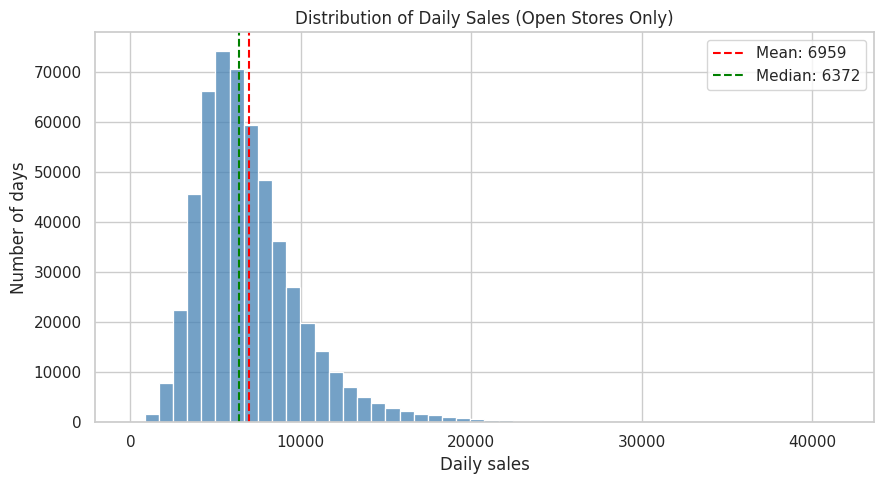

In [16]:
open_sales = df.loc[df["open"] == 1, "sales"]

plt.figure(figsize=(9, 5))
sns.histplot(open_sales, bins=50, color="steelblue")
plt.axvline(open_sales.mean(), color="red", linestyle="--", label="Mean: %.0f" % open_sales.mean())
plt.axvline(open_sales.median(), color="green", linestyle="--", label="Median: %.0f" % open_sales.median())
plt.title("Distribution of Daily Sales (Open Stores Only)")
plt.xlabel("Daily sales")
plt.ylabel("Number of days")
plt.legend()
plt.tight_layout()
plt.show()


**Plot 2 – Mean sales by month.** Show the seasonal trend: the average daily sales of open stores for each calendar month.

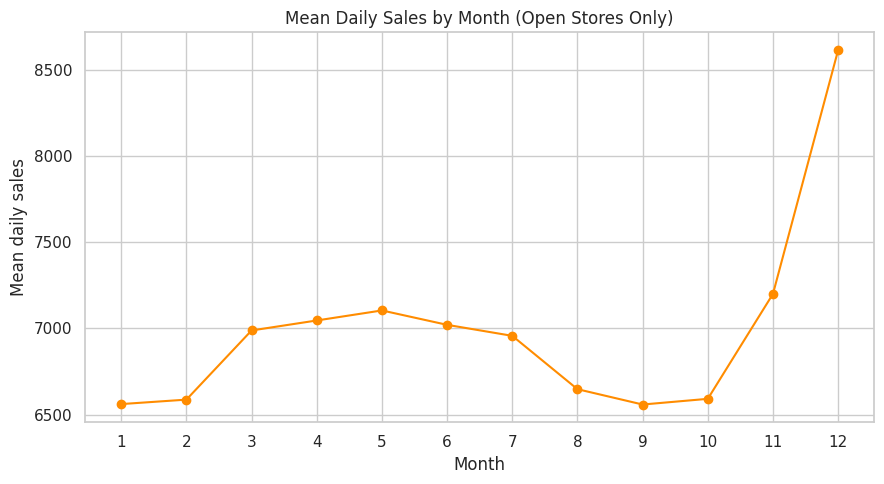

In [17]:
month_values = pd.to_datetime(df["date"]).dt.month
monthly = df.loc[df["open"] == 1].groupby(month_values[df["open"] == 1])["sales"].mean()

plt.figure(figsize=(9, 5))
plt.plot(monthly.index, monthly.values, marker="o", color="darkorange")
plt.xticks(range(1, 13))
plt.title("Mean Daily Sales by Month (Open Stores Only)")
plt.xlabel("Month")
plt.ylabel("Mean daily sales")
plt.tight_layout()
plt.show()


**Plot 3 – Feature importances.** Show which features the final Random Forest relies on most. Importances are available for tree models, which is not possible with the Linear Regression baseline.

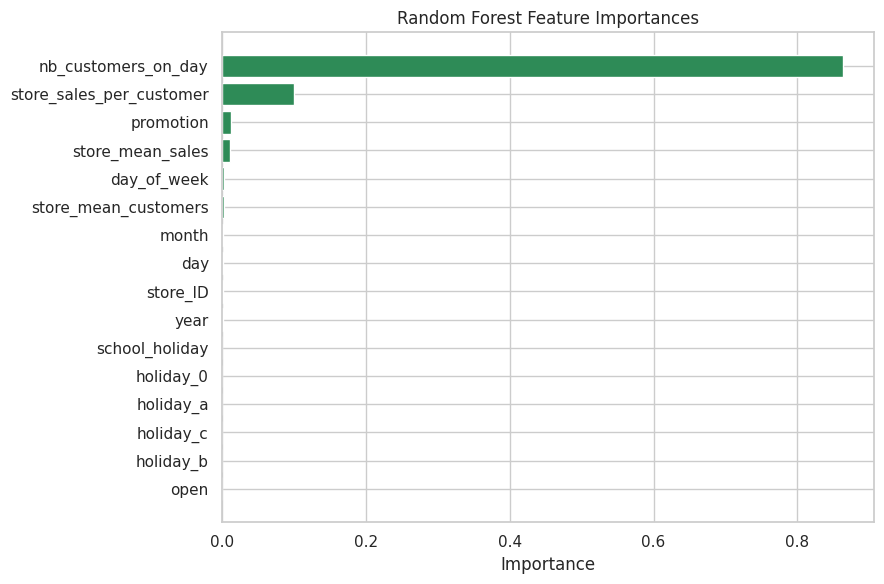

nb_customers_on_day         0.8633
store_sales_per_customer    0.1008
promotion                   0.0122
store_mean_sales            0.0110
day_of_week                 0.0033
dtype: float64


5314

In [18]:
importances = pd.Series(final_model.feature_importances_, index=feats).sort_values()

plt.figure(figsize=(9, 6))
plt.barh(importances.index, importances.values, color="seagreen")
plt.title("Random Forest Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

print(importances.sort_values(ascending=False).round(4).head(5))

# Release the final model to keep memory low before the next step.
del final_model
gc.collect()


Free the large prediction and full-data tables that are no longer needed, so the next step fits comfortably in memory.

In [19]:
del full_f, real_f, real_p, out, real, data, df, open_sales, month_values
gc.collect()


7011

**Plot 4 – Actual vs predicted sales.** Refit the same Random Forest settings on the training partition (51 trees, built as three averaged 17-tree forests to save memory), then compare actual and predicted sales on the held-out test set. Points close to the red line are good predictions.

Held-out R2: 0.9885


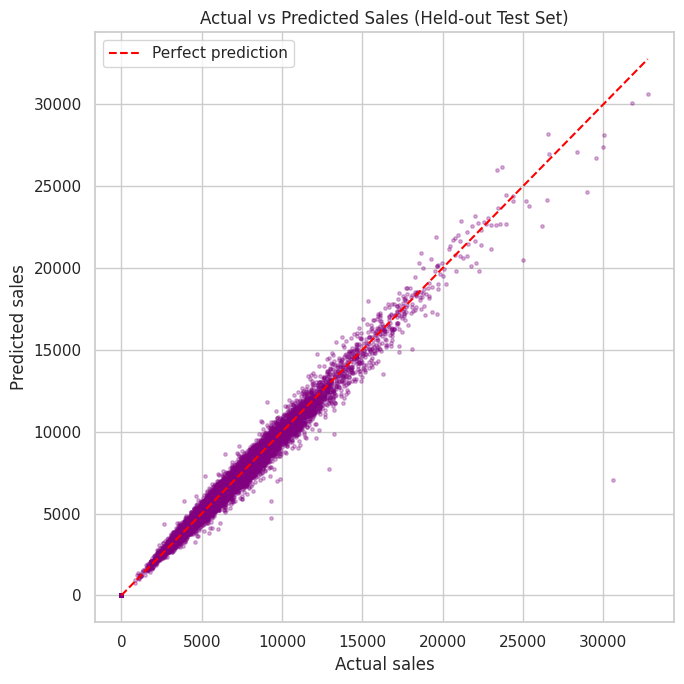

In [20]:
# Fit three 17-tree forests one after another and average their predictions.
# This equals one 51-tree Random Forest, but only one small forest is in memory at a time.
test_pred = np.zeros(len(test_f))
for seed in [10, 11, 12]:
    part = RandomForestRegressor(
        n_estimators=17, max_depth=25, min_samples_leaf=2,
        random_state=seed, n_jobs=1
    )
    part.fit(train_f[feats], train_f["sales"])
    test_pred += part.predict(test_f[feats]) / 3
    del part
    gc.collect()

print("Held-out R2:", round(r2_score(test_f["sales"], test_pred), 4))

sample = test_f.assign(pred=test_pred).sample(n=15000, random_state=10)

plt.figure(figsize=(7, 7))
plt.scatter(sample["sales"], sample["pred"], s=6, alpha=0.3, color="purple")
limit = max(sample["sales"].max(), sample["pred"].max())
plt.plot([0, limit], [0, limit], color="red", linestyle="--", label="Perfect prediction")
plt.title("Actual vs Predicted Sales (Held-out Test Set)")
plt.xlabel("Actual sales")
plt.ylabel("Predicted sales")
plt.legend()
plt.tight_layout()
plt.show()
